# 04 · Model Registry, Real-time Endpoint and Batch Inference
**AAI-540 Group 3 — CloudTrail Suspicious-Activity Classifier**

| | |
|---|---|
| **Goal** | Version the trained model in the **SageMaker Model Registry**, approve it, deploy it to a **real-time endpoint** (with data capture for monitoring) and score the full test year with a **batch transform** job. |
| **Input** | Model artefact + `evaluation.json` (notebook 03), `model-input/` CSVs and `encoder.json` |
| **Output** | Model package group `cloudtrail-risk-models` · endpoint `cloudtrail-risk-endpoint` · `batch-transform/output/` |
| **Next** | `05_monitoring.ipynb` (uses the endpoint created here) |

> ⚠️ **Cost:** the endpoint bills per hour while it exists (`ml.m5.large` ≈ US $0.12/h). Run notebook 05 right after this one and **delete the endpoint at the end of notebook 05**.

**Real-time vs batch — why both?** A security alert is only useful while it is actionable, so the primary interface is a **real-time endpoint** (one request = one or more 5-minute actor windows, answered in milliseconds). **Batch transform** covers back-fills and nightly re-scoring of a whole period without keeping a server running.

## 1. Setup

In [1]:
%%capture pip_log
# Install the project's pinned libraries (run once per kernel, BEFORE any other import).
# The pin keeps the SageMaker Python SDK on v2, which all notebooks in this repo use.
# Output is captured to keep the notebook clean; run print(pip_log.stdout) to see it.
# (Warnings about sagemaker-core / sagemaker-mlops conflicts refer to Studio's pre-installed
#  SDK v3 packages, which this project does not use.)
%pip install -q -r ../requirements.txt

In [2]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # shared project package: src/cloudtrail_mlops
DATA_DIR = Path.home() / "cloudtrail-data"           # local working copy, outside the git repo
DATA_DIR.mkdir(exist_ok=True)
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"] = "1"         # we intentionally pin SDK v2 (see requirements.txt)

import json
import time
from io import StringIO

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sagemaker import ModelPackage
from sagemaker.model import Model
from sagemaker.model_metrics import MetricsSource, ModelMetrics
from sagemaker.model_monitor import DataCaptureConfig

from cloudtrail_mlops import aws, config, dataset, evaluation, model
from cloudtrail_mlops.plots import BLUE, NORMAL, ORANGE, SUSPICIOUS, setup_style

setup_style()
ctx = aws.get_context()
state = aws.load_state(ctx)
sm_client = ctx.session.sagemaker_client
runtime = boto3.client("sagemaker-runtime", region_name=ctx.region)

MODEL_PACKAGE_GROUP = "cloudtrail-risk-models"
ENDPOINT_NAME = "cloudtrail-risk-endpoint"
ENDPOINT_INSTANCE = "ml.m5.large"     # ml.t2.medium is cheaper if your lab allows it

evaluation_report = json.loads(ctx.session.read_s3_file(ctx.bucket, state["evaluation_uri"].split(ctx.bucket + "/")[1]))
thresholds = state["thresholds"]
print("Model artefact:", state["model_data"])
print("Test metrics:", {k: round(v, 4) for k, v in evaluation_report["metrics"].items()})
print("Quality gate passed:", evaluation_report["quality_gate"]["passed"])

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
Model artefact: s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/training/tuning/ct-xgb-tune-261017-2220-008-9f779cba/output/model.tar.gz
Test metrics: {'test_roc_auc': 0.9587, 'test_average_precision': 0.3312, 'test_ap_lift': 58.7258, 'test_recall_medium': 0.7525}
Quality gate passed: True


## 2. Model Registry
A **model package group** holds every version of the model. Each version stores the artefact, the inference container, the supported instance types and the **evaluation metrics** (shown in Studio under *Models → Model registry → cloudtrail-risk-models*).

Versions are registered as `PendingManualApproval`. Approval is the manual gate of the CD process: only an **Approved** version may be deployed. Here we approve programmatically **only if the release gate passed** — in a real team a reviewer would click *Approve* in Studio.

In [3]:
try:
    sm_client.create_model_package_group(ModelPackageGroupName=MODEL_PACKAGE_GROUP,
                                         ModelPackageGroupDescription="CloudTrail suspicious-activity risk models (XGBoost)")
except sm_client.exceptions.ClientError as error:
    if "already exists" not in str(error).lower():
        raise

registrable = Model(image_uri=state["image_uri"], model_data=state["model_data"], role=ctx.role, sagemaker_session=ctx.session)
package = registrable.register(
    content_types=["text/csv"], response_types=["text/csv"],
    inference_instances=["ml.t2.medium", "ml.m5.large"], transform_instances=["ml.m5.large"],
    model_package_group_name=MODEL_PACKAGE_GROUP, approval_status="PendingManualApproval",
    model_metrics=ModelMetrics(model_statistics=MetricsSource(s3_uri=state["evaluation_uri"], content_type="application/json")),
    description=(f"XGBoost actor x 5-min window risk model | test ROC-AUC {evaluation_report['metrics']['test_roc_auc']:.3f} "
                 f"| AP lift {evaluation_report['metrics']['test_ap_lift']:.1f}x | job {state['best_training_job']}"),
    customer_metadata_properties={"training_job": state["best_training_job"],
                                  "threshold_medium": f"{thresholds['medium']:.6f}", "threshold_high": f"{thresholds['high']:.6f}"},
)
package_arn = package.model_package_arn
print("Registered:", package_arn)

Registered: arn:aws:sagemaker:us-east-1:674905628044:model-package/cloudtrail-risk-models/1


In [4]:
if evaluation_report["quality_gate"]["passed"]:
    sm_client.update_model_package(ModelPackageArn=package_arn, ModelApprovalStatus="Approved",
                                   ApprovalDescription="Release gate passed (ROC-AUC and AP lift) and results reviewed")
else:
    raise RuntimeError("Release gate failed - the model stays PendingManualApproval and must not be deployed")

versions = sm_client.list_model_packages(ModelPackageGroupName=MODEL_PACKAGE_GROUP, SortBy="CreationTime", SortOrder="Descending")
aws.save_state(ctx, model_package_group=MODEL_PACKAGE_GROUP, model_package_arn=package_arn)
pd.DataFrame(versions["ModelPackageSummaryList"])[["ModelPackageVersion", "ModelApprovalStatus", "CreationTime", "ModelPackageDescription"]]

,ModelPackageVersion,ModelApprovalStatus,CreationTime,ModelPackageDescription
0,1,Approved,2026-10-17 22:57:49.294000+00:00,XGBoost actor x 5-min window risk model | test...


## 3. Deploy the approved version to a real-time endpoint
**Data capture** saves every request and response to S3 (`monitoring/datacapture/`). SageMaker Model Monitor (notebook 05) compares this live traffic with the training baseline to detect data drift. Deployment takes ~5–8 minutes.

In [5]:
capture = DataCaptureConfig(enable_capture=True, sampling_percentage=100,
                            destination_s3_uri=ctx.s3_uri("datacapture"), sagemaker_session=ctx.session)
approved = ModelPackage(role=ctx.role, model_package_arn=package_arn, sagemaker_session=ctx.session)
existing = {e["EndpointName"] for e in sm_client.list_endpoints(NameContains=ENDPOINT_NAME)["Endpoints"]}
if ENDPOINT_NAME in existing:
    print(f"Endpoint {ENDPOINT_NAME} already exists - reusing it (delete it first to redeploy a new version)")
else:
    approved.deploy(initial_instance_count=1, instance_type=ENDPOINT_INSTANCE, endpoint_name=ENDPOINT_NAME,
                    data_capture_config=capture, wait=True)
aws.save_state(ctx, endpoint_name=ENDPOINT_NAME)

endpoint = sm_client.describe_endpoint(EndpointName=ENDPOINT_NAME)
print(endpoint["EndpointName"], "->", endpoint["EndpointStatus"], "| data capture:", endpoint["DataCaptureConfig"]["EnableCapture"])

------!cloudtrail-risk-endpoint -> InService | data capture: True


## 4. Real-time inference
The endpoint receives **encoded feature rows** as CSV (one row per actor-window, columns in `encoder.feature_names` order) and returns one risk score per row.

The cell below shows the full path a production caller would follow:
1. take raw actor-window features (here: real windows from 2020, which the model has never seen),
2. encode them with the saved `encoder.json` (identical to training),
3. call the endpoint,
4. turn the score into a **risk level** using the analyst-capacity thresholds.

In [6]:
encoder_path = DATA_DIR / "model-input" / "encoder.json"
if not encoder_path.exists():
    ctx.session.download_data(str(encoder_path.parent), bucket=ctx.bucket, key_prefix=ctx.prefix("model_input") + "/encoder.json")
encoder = dataset.FeatureEncoder.load(encoder_path)

mart = dataset.load_mart(DATA_DIR / "features" / "feature_mart.parquet")
test_windows = dataset.chronological_split(mart)["test"]
# a few suspicious and a few normal windows from 2020
sample = pd.concat([test_windows[test_windows[config.TARGET_COLUMN] == 1].sample(5, random_state=1),
                    test_windows[test_windows[config.TARGET_COLUMN] == 0].sample(5, random_state=1)])


def risk_level(score):
    return "HIGH" if score >= thresholds["high"] else "MEDIUM" if score >= thresholds["medium"] else "LOW"


def score_windows(windows: pd.DataFrame) -> np.ndarray:
    """Encode raw actor-window features and score them on the real-time endpoint."""
    payload = encoder.transform(windows).to_csv(header=False, index=False, float_format="%.6g")
    response = runtime.invoke_endpoint(EndpointName=ENDPOINT_NAME, ContentType="text/csv", Body=payload)
    body = response["Body"].read().decode().strip()
    return np.array([float(v) for v in body.replace("\n", ",").split(",") if v])


start = time.perf_counter()
endpoint_scores = score_windows(sample)
latency_ms = (time.perf_counter() - start) * 1000

result = sample[["actor_id", "window_start", "distinct_apis", "write_count", "auth_error_count", config.TARGET_COLUMN]].copy()
result["risk_score"] = endpoint_scores.round(4)
result["risk_level"] = [risk_level(s) for s in endpoint_scores]
print(f"Scored {len(sample)} windows in one request: {latency_ms:.0f} ms round trip")
result.rename(columns={config.TARGET_COLUMN: "weak_label"})

Scored 10 windows in one request: 541 ms round trip


,actor_id,window_start,distinct_apis,write_count,auth_error_count,weak_label,risk_score,risk_level
17401,254.9.176.211,2020-10-01 02:00:00+00:00,16,8.0,15.0,1,0.3540,MEDIUM
16288,254.9.176.211,2020-09-16 02:00:00+00:00,16,8.0,15.0,1,0.3876,HIGH
6159,arn:aws:iam::811596193553:user/Level6,2020-04-02 12:05:00+00:00,1,0.0,0.0,1,0.3310,LOW
17811,arn:aws:iam::811596193553:root,2020-10-07 15:50:00+00:00,16,1.0,0.0,1,0.5976,HIGH
10742,arn:aws:iam::811596193553:user/backup,2020-06-10 21:45:00+00:00,1,1.0,1.0,1,0.3471,MEDIUM
1262,ec2.amazonaws.com,2020-01-21 23:25:00+00:00,1,0.0,0.0,0,0.3068,LOW
12814,ec2.amazonaws.com,2020-07-17 04:35:00+00:00,1,0.0,0.0,0,0.3068,LOW
10300,ec2.amazonaws.com,2020-06-04 09:50:00+00:00,1,0.0,0.0,0,0.3068,LOW
8424,ec2.amazonaws.com,2020-05-05 20:30:00+00:00,1,0.0,0.0,0,0.3068,LOW
15943,ec2.amazonaws.com,2020-09-10 19:40:00+00:00,1,0.0,0.0,0,0.3068,LOW


**Parity check** — the endpoint must return the same scores as the model validated in notebook 03:

In [7]:
local_dir = DATA_DIR / "model"
if not (local_dir / "xgboost-model").exists():
    uri = state["model_data"]
    ctx.session.download_data(str(local_dir), bucket=uri.split("/")[2], key_prefix="/".join(uri.split("/")[3:]))
    model.extract_model(local_dir / "model.tar.gz", local_dir)
local_scores = model.predict(model.load_booster(local_dir / "xgboost-model"), encoder.transform(sample))
difference = np.abs(local_scores - endpoint_scores).max()
print(f"max |endpoint - local| = {difference:.2e}", "-> parity OK" if difference < 1e-4 else "-> CHECK: scores differ")

max |endpoint - local| = 0.00e+00 -> parity OK


### 4.1 Generate realistic traffic
To populate the CloudWatch metrics and the data-capture log used by notebook 05, we replay 1,000 windows from 2020 against the endpoint, one window per request (as a live event stream would).

In [8]:
replay = test_windows.sample(1000, random_state=7)
latencies = []
for i in range(len(replay)):
    start = time.perf_counter()
    score_windows(replay.iloc[[i]])
    latencies.append((time.perf_counter() - start) * 1000)
print(f"{len(latencies)} requests | client-side latency p50 {np.percentile(latencies, 50):.0f} ms, "
      f"p95 {np.percentile(latencies, 95):.0f} ms")

1000 requests | client-side latency p50 22 ms, p95 29 ms


## 5. Batch transform — score the whole test year offline
A batch transform job starts its own instance, scores every row of `test_features.csv`, writes the results to S3 and shuts down. We then join the scores with the labels and actor keys and confirm the batch path reproduces the evaluation of notebook 03.

In [9]:
transformer = approved.transformer(instance_count=1, instance_type="ml.m5.large", strategy="MultiRecord",
                                   assemble_with="Line", accept="text/csv",
                                   output_path=ctx.s3_uri("batch", "output"))
transformer.transform(data=f"{state['model_input_uri']}/test/test_features.csv", content_type="text/csv",
                      split_type="Line", wait=True, logs=False)
batch_job = transformer.latest_transform_job.name
print("Batch transform job:", batch_job)

INFO:sagemaker:Creating transform job with name: cloudtrail-risk-models-2026-10-17-23-01-48-945


....................................................!
Batch transform job: cloudtrail-risk-models-2026-10-17-23-01-48-945


In [10]:
output_key = f"{ctx.prefix('batch')}/output/test_features.csv.out"
batch_scores = pd.read_csv(StringIO(ctx.session.read_s3_file(ctx.bucket, output_key)), header=None)[0].to_numpy()
labels = pd.read_csv(DATA_DIR / "model-input" / "test" / "test_labels.csv")["label"].to_numpy()
keys = pd.read_csv(DATA_DIR / "model-input" / "metadata" / "test_metadata.csv")
assert len(batch_scores) == len(labels) == len(keys)

batch = keys.assign(risk_score=batch_scores, weak_label=labels)
batch["risk_level"] = [risk_level(s) for s in batch_scores]
batch_metrics = evaluation.classification_metrics(labels, batch_scores, thresholds["medium"])
print(f"Batch output: {len(batch):,} rows -> s3://{ctx.bucket}/{output_key}")
print(f"Batch ROC-AUC {batch_metrics['roc_auc']:.4f} (notebook 03: {evaluation_report['metrics']['test_roc_auc']:.4f}) | "
      f"AP {batch_metrics['average_precision']:.4f} (notebook 03: {evaluation_report['metrics']['test_average_precision']:.4f})")
display(batch.risk_level.value_counts().to_frame("windows"))
batch.sort_values("risk_score", ascending=False).head(10)

Batch output: 17,908 rows -> s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/batch-transform/output/test_features.csv.out
Batch ROC-AUC 0.9587 (notebook 03: 0.9587) | AP 0.3312 (notebook 03: 0.3312)


,windows
risk_level,
LOW,16936
MEDIUM,633
HIGH,339


,actor_id,window_start,risk_score,weak_label,risk_level
9387,arn:aws:iam::811596193553:root,2020-05-22 18:05:00+00:00,0.677377,1,HIGH
14000,arn:aws:iam::811596193553:root,2020-08-06 15:55:00+00:00,0.677377,1,HIGH
1091,8.101.151.38,2020-01-18 07:30:00+00:00,0.656235,1,HIGH
808,222.230.154.255,2020-01-15 10:05:00+00:00,0.656235,1,HIGH
17811,arn:aws:iam::811596193553:root,2020-10-07 15:50:00+00:00,0.597621,1,HIGH
17758,arn:aws:iam::811596193553:root,2020-10-06 21:10:00+00:00,0.587911,1,HIGH
6824,arn:aws:iam::811596193553:user/backup,2020-04-10 14:55:00+00:00,0.500567,0,HIGH
14849,arn:aws:sts::811596193553:assumed-role/aws:ec2...,2020-08-21 07:50:00+00:00,0.500018,0,HIGH
6412,arn:aws:iam::811596193553:user/Level6,2020-04-04 17:10:00+00:00,0.491827,0,HIGH
6825,arn:aws:iam::811596193553:user/backup,2020-04-10 15:00:00+00:00,0.490896,0,HIGH


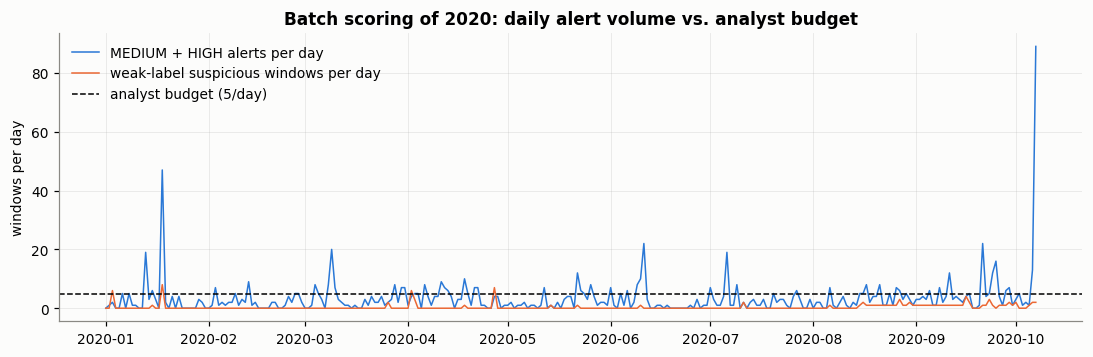

{'raw_uri': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/raw/flaws_cloudtrail_logs.tar',
 'events_uri': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/processed/events',
 'feature_mart_parquet': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/features/feature_mart.parquet',
 'feature_mart_csv': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/features/csv/feature_mart.csv',
 'feature_group': 'cloudtrail-actor-window-features',
 'model_input_uri': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/model-input',
 'best_training_job': 'ct-xgb-tune-261017-2220-008-9f779cba',
 'model_data': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/training/tuning/ct-xgb-tune-261017-2220-008-9f779cba/output/model.tar.gz',
 'evaluation_uri': 's3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/training/evaluation/evaluation.json',
 'thresholds': {'medium': 0.3337774872779846, 'high': 0.3614203929901123},
 'image_uri': '683313688378.dkr.ecr.us-east-1.am

In [11]:
daily = batch.assign(day=pd.to_datetime(batch.window_start, utc=True).dt.floor("D"))
daily = daily.groupby("day").agg(alerts=("risk_level", lambda s: (s != "LOW").sum()), suspicious=("weak_label", "sum"))
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(daily.index, daily.alerts, color=BLUE, lw=1, label="MEDIUM + HIGH alerts per day")
ax.plot(daily.index, daily.suspicious, color=ORANGE, lw=1, label="weak-label suspicious windows per day")
ax.axhline(config.MEDIUM_ALERTS_PER_DAY, color="black", ls="--", lw=1, label="analyst budget (5/day)")
ax.set(title="Batch scoring of 2020: daily alert volume vs. analyst budget", ylabel="windows per day")
ax.legend(loc="upper left")
plt.show()
aws.save_state(ctx, batch_transform_job=batch_job, batch_output=f"s3://{ctx.bucket}/{output_key}")

## 6. Summary
* **Model Registry:** version 1 of `cloudtrail-risk-models` registered with its evaluation metrics and **approved** because the release gate passed.
* **Real-time endpoint** `cloudtrail-risk-endpoint` (`ml.m5.large`, data capture on): endpoint scores are **identical to the validated model** (max difference 0.0); single-window requests take **22 ms (p50) / 29 ms (p95)** round trip.
* In the 10-window demo, 4 of 5 suspicious windows were flagged MEDIUM or HIGH and all 5 normal windows stayed LOW; the missed one (user `Level6`, April 2020) is from the month where recall is weakest (notebook 03).
* **Batch transform** scored all **17,908** windows of 2020 and reproduced the offline metrics exactly (ROC-AUC 0.9587, AP 0.3312): 339 HIGH, 633 MEDIUM, 16,936 LOW. The top 6 batch alerts are all true weak-label positives (root-account activity and two external IPs).

➡️ Continue with **notebook 05** now — it monitors this endpoint and deletes it at the end.